# Week 2: Feature Engineering and the Leakage Audit

<sub>[Previous: Exploratory Data Analysis and Visualization](week1_03_eda_and_visualization.ipynb)</sub>  
<sub>The tested code these notebooks import is documented in [the project code reference](week1_00_project_code_reference.ipynb).</sub>

Week 1 ended with a warning to myself: the legitimate pre-delivery signals in this data are individually weak, so when we start modeling the temptation to reach for a field that *looks* predictive will be strong. This week is about building the feature set the right way, and proving that the discipline actually holds. I think this is the single most important engineering decision in the whole project, so it gets its own week.

### Contents

1. [Where Week 1 left us](#recap)
2. [The one column that decides everything: timing](#timing)
3. [The leakage trap, measured](#leak)
4. [Building the leakage-safe feature matrix](#matrix)
5. [Why these features, one by one](#why)
6. [The guards that keep it honest](#guards)
7. [The equity audit on the complete population](#equity)
8. [The plan from here](#plan)

### Setup

A short, documented setup. First the imports. This week is heavier than Week 1 because the leakage audit needs the full raw certificate schema, so we read the complete per-year cleaned files with Polars (fast and memory-light) rather than the slim exploration table.

In [1]:
# Week 2 is feature engineering and the leakage audit. Unlike Week 1 (which used a slim 17-field
# exploration table), this week we need the FULL raw certificate schema, because the leakage question
# is precisely about which raw fields we are allowed to keep. So we load the complete per-year cleaned
# files (all singletons, 2018-2024, every raw column) and lean on the project's own tested pipeline.
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
RNG = 7


We reuse the project's own tested code rather than rewriting it in the notebook. `build_modeling_frame` builds the leakage-safe feature matrix, `excluded_vars_detector_auc` is the automated leakage gate, and `schema` holds the leakage classification (which raw columns are barred and why). If any of these drift, the test suite fails, not just the notebook.

In [2]:
# The tested project modules. We do NOT re-implement cleaning, feature building, or the leakage gates
# in the notebook: we call the same code the test suite covers, so the notebook cannot drift from it.
import sys
sys.path.insert(0, str(Path("..") / "src"))
from equibirth.features.build import build_modeling_frame
from equibirth.features.leakage import excluded_vars_detector_auc, univariate_auc
from equibirth.ingest import schema

INTERIM = Path("..") / "data" / "interim"
YEARS = [2018, 2019, 2020, 2021, 2022, 2023, 2024]

def load_years(years):
    # Concatenate LAZILY and collect once, so Polars never holds seven materialized frames plus a
    # concatenated copy at the same time (that doubled peak memory risked the kernel on this machine).
    frames = [pl.scan_parquet(INTERIM / f"natality{y}_clean.parquet").with_columns(pl.lit(y).alias("birth_year"))
              for y in years]
    return pl.concat(frames, how="diagonal_relaxed").collect()


The same Okabe-Ito palette and matplotlib house style as Week 1, so the two weeks read as one continuous piece of work.

In [3]:
# The same Okabe-Ito palette and house style as Week 1, so the whole project looks like one piece.
PALETTE = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00",
           "purple": "#CC79A7", "sky": "#56B4E9", "yellow": "#F0E442", "grey": "#999999",
           "ink": "#1a1a2e"}
RACE_ORDER = ["NH White", "NH Asian", "Hispanic", "NH Multiracial", "NH NHOPI", "NH AIAN", "NH Black"]
RACE_COLOR = {r: PALETTE["grey"] for r in RACE_ORDER}
RACE_COLOR.update({"NH White": PALETTE["blue"], "NH Black": PALETTE["red"],
                   "Hispanic": PALETTE["green"], "NH Asian": PALETTE["orange"]})

plt.rcParams.update({"figure.figsize": (8.6, 4.8), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
                     "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
                     "axes.titlepad": 10, "font.family": "DejaVu Sans"})

def style(ax, title, xlabel, ylabel):
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    return ax


<a id="recap"></a>
## Where Week 1 left us

Two facts from Week 1 set up everything here. First, on the complete 2018-2024 files, about **8.6% of singleton births are preterm**, and every recorded field correlates only weakly with the outcome (the strongest, prior preterm birth, reaches about +0.13). Second, there is a large racial disparity that education does not close. Let me reload the full data and confirm the headline rate live before building anything on top of it.

In [4]:
import gc
df = load_years(YEARS)
valid = df.filter(pl.col('preterm').is_not_null())
# Capture the raw shape/columns, then free the ~3GB full frame: everything below works from
# 'valid' (same columns) and a 300K sample, so keeping 'df' resident only risks the kernel.
raw_rows, raw_cols, RAW_COLUMNS = df.height, df.width, df.columns
del df; gc.collect()
print(f'Complete singleton population 2018-2024: {raw_rows:,} rows x {raw_cols} raw columns')
print(f'Overall singleton preterm rate: {valid["preterm"].mean()*100:.2f}%')

Complete singleton population 2018-2024: 24,941,021 rows x 84 raw columns
Overall singleton preterm rate: 8.57%


About 8.6% across roughly 24.9 million singleton births, matching Week 1 exactly. Now the central question: which of these raw columns are we actually allowed to use?

<a id="timing"></a>
## The one column that decides everything: timing

A field is only a fair predictor if it is known *before* delivery. That single property, timing, splits the certificate into three kinds of field:

1. **Pre-delivery and legitimate**: fixed before or early in pregnancy. Maternal age, education, race, pre-pregnancy BMI, prior preterm birth, pre-pregnancy diabetes and hypertension, smoking. These are fair game.
2. **Timing-conditional**: known during pregnancy but entangled with how the pregnancy unfolds. WIC enrollment, the month prenatal care began. We keep these only with a caveat and a statistical gate (below).
3. **Post-delivery or outcome-entangled**: recorded at or after birth, or given *because* preterm was anticipated. Birthweight, Apgar score, NICU admission, labor interventions like antenatal steroids, and the total prenatal-visit count (which is mechanically capped by how long the pregnancy lasts). These are barred.

The project encodes this classification in code, not prose, so it is testable. Let me show the barred list is real and sizable.

In [5]:
excluded = sorted(schema.LEAKAGE_DETECTOR_VARS)
print(f'{len(excluded)} raw columns are classified as post-delivery / outcome-entangled and BARRED:')
print(', '.join(excluded[:18]), '...')
present = [c for c in excluded if c in RAW_COLUMNS]
print(f'\n{len(present)} of them are physically present in our files (so they COULD leak in if we were careless).')

50 raw columns are classified as post-delivery / outcome-entangled and BARRED:
ab_anti, ab_aven1, ab_aven6, ab_nicu, ab_seiz, ab_surf, apgar10, apgar10r, apgar5, apgar5r, attend, bfacil, bfacil3, bwtr12, bwtr4, ca_anen, ca_cchd, ca_cdh ...

50 of them are physically present in our files (so they COULD leak in if we were careless).


So the danger is concrete: dozens of these near-perfect predictors sit right there in the raw file. The question is what happens if we let them in. Rather than argue about it, let me measure it.

<a id="leak"></a>
## The leakage trap, measured

Here is the experiment that motivates the entire week. I train a simple classifier on the **barred post-delivery variables alone** (birthweight, Apgar, labor interventions, and the rest) and see how well it predicts preterm birth. If leakage is a real danger, this model should look fantastic, which would be exactly the problem: it is predicting an outcome using information that only exists *after* the outcome. I run it on a manageable random slice for speed; the full-data audit script gets the same answer.

In [6]:
demo = valid.sample(n=300_000, seed=RNG)
leak_auc = excluded_vars_detector_auc(demo, target='preterm')
print(f'AUC of a model trained on the BARRED post-delivery fields alone: {leak_auc:.3f}')
print(f'Project leakage gate (build fails above this): {0.55}')
print('Verdict:', 'LEAKAGE DETECTED (as expected) - these fields are barred' if leak_auc > 0.55 else 'no leak')

AUC of a model trained on the BARRED post-delivery fields alone: 0.919
Project leakage gate (build fails above this): 0.55
Verdict: LEAKAGE DETECTED (as expected) - these fields are barred


**About 0.92.** That is the whole lesson in one number. A preterm model built entirely from fields recorded at or after delivery looks near-perfect, and it is worthless, because at the moment a real prediction would be made none of those fields exist yet. This is not a hypothetical: it is the difference between an honest project and one that quietly cheats. The project turns this into an automated gate: any candidate feature set whose barred-variable detector clears 0.55 AUC fails the build. A clean model built only from legitimate pre-delivery fields should land far lower, given how weak the Week 1 signals were, and the gap between that honest number and this near-perfect leaky one is exactly what the coming weeks are set up to measure. Getting the honest number, whatever it turns out to be, is the point.

The combined 0.92 is damning, but it hides which fields do the damage. So let me take each barred field on its own and ask a narrower question: how well does that single column, with nothing else, predict preterm? A field that scores high alone is not just guilty by association with the set; it is a leak in its own right. This is why the exclusion list bars each field individually, not merely the group.

In [7]:
leaky_fields = ['dbwt', 'apgar5', 'ab_nicu', 'ld_ster', 'previs', 'me_rout']
present = [c for c in leaky_fields if c in demo.columns]
print("How strong is each BARRED field ALONE at predicting preterm (univariate AUC)?")
rows = []
for c in present:
    au = univariate_auc(demo, c, target='preterm')
    rows.append((c, au))
for c, au in sorted(rows, key=lambda r: -r[1]):
    print(f"  {c:<10} univariate AUC = {au:.3f}")
print(f"\nCombined, these reach ~{leak_auc:.2f}. Individually several already dwarf the honest "
      "pre-delivery ceiling (which the coming weeks will show lands near 0.65), which is why each is "
      "barred, not just the set.")

How strong is each BARRED field ALONE at predicting preterm (univariate AUC)?


  dbwt       univariate AUC = 0.884
  ab_nicu    univariate AUC = 0.719
  previs     univariate AUC = 0.668
  ld_ster    univariate AUC = 0.638
  apgar5     univariate AUC = 0.619
  me_rout    univariate AUC = 0.594

Combined, these reach ~0.92. Individually several already dwarf the honest pre-delivery ceiling (which the coming weeks will show lands near 0.65), which is why each is barred, not just the set.


Read top to bottom, this is the leakage story field by field. **Birthweight (`dbwt`) alone scores about 0.89**, nearly the entire combined signal, because it is recorded at delivery and is largely a consequence of how long the pregnancy lasted (more on this next). **NICU admission (`ab_nicu`, about 0.72)** happens after birth and is far more likely for a preterm infant. **Antenatal steroids (`ld_ster`, about 0.64)** are given precisely because a preterm delivery was anticipated, so the field encodes the clinician's expectation of the outcome. **Total prenatal visits (`previs`, about 0.67)** are mechanically capped by gestation length. **The 5-minute Apgar (`apgar5`, about 0.62)** is scored 5 minutes after the baby is out, and **delivery route (`me_rout`, about 0.59)** is recorded at delivery. Every one of them is known only at or after birth, and several on their own already clear a bar that an honest pre-delivery model is unlikely to reach. The coming weeks will report that honest ceiling; I expect it near 0.65, but that is a forward look, not a result yet.

Birthweight is worth pausing on, because it is the single most tempting field to keep: it is numeric, always present, and enormously predictive. That is exactly the trap. Let me show *why* it predicts so well, which is the whole reason it cannot be used.

In [8]:
bw = (valid.filter(pl.col('dbwt').is_not_null() & (pl.col('dbwt') < 9000))
        .group_by('preterm').agg(mean_bw=pl.col('dbwt').mean(), n=pl.len()).sort('preterm'))
print("Mean birthweight (grams) by outcome (why dbwt leaks):")
for r in bw.iter_rows(named=True):
    lab = 'preterm' if r['preterm'] == 1 else 'term'
    print(f"  {lab:<8} {r['mean_bw']:.0f} g   (n={r['n']:,})")
print("\nBirthweight is largely a CONSEQUENCE of gestation length, so a model using it is reading the "
      "answer off the outcome. It is recorded at delivery and cannot exist when a prediction is made.")

Mean birthweight (grams) by outcome (why dbwt leaks):
  term     3364 g   (n=22,779,602)
  preterm  2379 g   (n=2,127,315)

Birthweight is largely a CONSEQUENCE of gestation length, so a model using it is reading the answer off the outcome. It is recorded at delivery and cannot exist when a prediction is made.


Preterm infants average roughly 2,400 grams against roughly 3,400 for term, a gap of about a kilogram. That is not a subtle correlation a model has to work to find; it is close to reverse causation. Birthweight accrues over the weeks of gestation, so a shorter pregnancy mechanically produces a lighter baby. Using `dbwt` to predict preterm is therefore close to using the outcome to predict itself, and the field does not even exist at the moment a real prediction would be made (before the birth). This is why it is barred despite being the most predictive single column in the file.

The prenatal-visit count deserves the same scrutiny, for a subtler reason. Total prenatal visits are mechanically capped by how long the pregnancy lasts: a delivery at 30 weeks simply cannot accumulate as many visits as one at 40 weeks, regardless of the mother's engagement with care. So the tempting reading, *fewer visits implies higher preterm risk*, is partly an artifact of the outcome shortening the window in which visits could occur (the reverse-causal direction the Kotelchuck / APNCU adequacy-of-care literature is careful about: [APNCU index overview](https://www.mchlibrary.org/databases/HSNRCPDFs/Overview_APCUIndex.pdf)). That is why `previs` and any APNCU-style adequacy recode built on the raw visit count are barred, and why the pipeline keeps only a gated binary first-trimester-care flag, which records *when* care began rather than *how many* visits the (possibly shortened) pregnancy allowed.

<a id="matrix"></a>
## Building the leakage-safe feature matrix

Now the constructive half. I call the tested `build_modeling_frame`, which keeps only legitimate pre-delivery and (gated) timing-conditional fields, and engineers a few features on top: age brackets (the age relationship is U-shaped, not linear), a medical-risk count, and a race-by-education interaction to capture the intersectional structure Week 1 hinted at. Every engineered feature declares which raw columns it is built from, which matters for the guard in the next section.

In [9]:
X, y, components = build_modeling_frame(demo)
print(f'Leakage-safe primary matrix: {X.height:,} rows x {X.width} features')
print('\nA few of the engineered / encoded features:')
print([c for c in X.columns if c in ('medical_risk_count','age_bracket','married','first_trimester_care')])
print('\nExample: the medical-risk count is built from exactly these raw flags (enumerated, no leak):')
print(components['medical_risk_count'])

Leakage-safe primary matrix: 300,000 rows x 103 features

A few of the engineered / encoded features:
['married', 'medical_risk_count', 'age_bracket', 'first_trimester_care']

Example: the medical-risk count is built from exactly these raw flags (enumerated, no leak):
('rf_pdiab', 'rf_phype', 'rf_ppterm', 'rf_cesar')


Note what is *not* there. None of the barred fields appear, and the medical-risk composite is an explicit, enumerated sum of four pre-pregnancy flags (pre-pregnancy diabetes, pre-pregnancy hypertension, prior preterm birth, prior cesarean), with gestational diabetes deliberately excluded because it is diagnosed mid-pregnancy and can *cause* a preterm delivery through induction. That care matters: a composite is a classic way for a leaky field to sneak in through the back door.

A word on the encoding choices `build_modeling_frame` makes, since they are the context the later modeling notebooks rely on and they are deliberate rather than default:

- **Ordinal for education.** Education is genuinely ordered (more schooling is a rank, not an unordered label), so it stays a single ordered numeric rather than exploding into one-hot columns.
- **One-hot for the nominal categoricals**: race/ethnicity, payment source, and marital status. These have no natural order, so encoding them as ordered integers would invent a ranking that is not there.
- **Kept numeric** for the genuinely continuous fields: maternal age, pre-pregnancy BMI, and the parity counts (prior live and prior dead births). Age is *also* kept as a U-shaped bracket alongside the raw value, because risk rises at both the young and older ends.
- **Y/N flags mapped to 1/0**, with anything else (including the 'U' unknown code) left null rather than silently coerced to 0.
- **The enumerated medical-risk composite**: exactly pre-pregnancy diabetes + pre-pregnancy hypertension + prior preterm + prior cesarean. Gestational diabetes is deliberately EXCLUDED because it is diagnosed mid-pregnancy and is a timing leak (it can cause a preterm delivery through induction), so it is not a fair pre-pregnancy predictor.

One thing that has *already* happened, upstream, and does not clutter this layer: de-sentinelling. Birth-certificate 'unknown / not stated' codes (a per-variable map in the ingest step, never a single global value, so a legitimate 9 prenatal visits or parity 9 survives) were converted to true nulls when the cleaned files were written. So the feature layer sees honest nulls, not sentinel numbers masquerading as data, and imputation is left to model time (a PLANNED step for the modeling weeks) rather than being baked in here.

Finally, the same medical-risk gradient I sketched in Week 1 as an exploratory cross-tab, now recomputed on the FULL population as the exact engineered composite the pipeline builds (the enumerated sum of the four pre-pregnancy flags). If the feature is worth engineering, it should show a clean dose-response: more risk flags, higher preterm rate.

In [10]:
mr = (valid.with_columns(
        pl.sum_horizontal([(pl.col(c).str.to_uppercase() == "Y").cast(pl.Int8)
                           for c in schema.MEDICAL_RISK_COMPOSITE_COMPONENTS if c in valid.columns])
        .alias('risk_n'))
      .group_by('risk_n').agg(rate=pl.col('preterm').mean(), n=pl.len()).sort('risk_n'))
print("Medical-risk count vs preterm rate (full data; the composite the pipeline builds):")
for r in mr.iter_rows(named=True):
    print(f"  {int(r['risk_n'])} flags: {r['rate']*100:5.1f}%   (n={r['n']:,})")

Medical-risk count vs preterm rate (full data; the composite the pipeline builds):
  0 flags:   7.3%   (n=19,885,859)
  1 flags:  11.8%   (n=4,444,245)
  2 flags:  26.4%   (n=533,887)
  3 flags:  43.0%   (n=52,182)
  4 flags:  60.9%   (n=4,234)


A clean, monotone gradient on all 24.9 million singletons: the preterm rate climbs from about 8% at 0 flags toward roughly 60% at 4 flags. That is exactly the shape that makes the composite worth engineering, and it confirms the Week 1 exploratory finding now as a first class feature on the full data rather than a sample. The reading is strictly associational: these are pre-pregnancy conditions correlated with the outcome, not a causal or clinical claim, and the small-count high-flag cells carry wide uncertainty.

<a id="why"></a>
## Why these features, one by one

The feature matrix above is not a default dump of every column in the file. It is a set of deliberate decisions, and each one has a reason rooted in two questions: is the field known *before* delivery (timing), and what is the mechanism that links it to the outcome? So here is each decision laid out. To keep the table honest I build it live from the pipeline's own `components` map (which records the raw source column behind every emitted feature) and from the schema's leakage classification, so the table cannot drift away from the code that actually runs. The roughly 100 columns are grouped into feature *families* (the one-hot race columns are one family, the race-by-education interaction is another, and so on) so the story is readable rather than 100 near-identical rows.

In [11]:
# Built LIVE from `components` (feature -> raw source columns) and `schema`, so it cannot drift.
# Classify each emitted feature into a family, then print one row per family with its source,
# an IN verdict, how many columns it expands to, and the reason it is kept.
def _family(feat, src):
    if feat.startswith('mother_race_ethnicity_'): return 'one-hot race / ethnicity'
    if feat.startswith('race_education'):          return 'race x education interaction'
    if feat.startswith('pay_'):                    return 'one-hot payment source'
    if feat in ('medical_risk_count',):            return 'engineered medical-risk count'
    if feat in ('age_bracket',):                   return 'engineered age bracket'
    if feat in ('married',):                       return 'marital status'
    if feat in ('wic', 'first_trimester_care'):    return 'timing-conditional (gated)'
    if feat in ('rf_pdiab','rf_phype','rf_ppterm','rf_cesar'): return 'medical-history Y/N flags'
    return 'numeric demographics'
REASON = {
    'numeric demographics': 'Fixed before or early in pregnancy; kept as continuous numerics.',
    'marital status': 'Pre-delivery social field; binary married flag from dmar.',
    'medical-history Y/N flags': 'Pre-pregnancy conditions, known before conception.',
    'engineered medical-risk count': 'Enumerated sum of the four pre-pregnancy flags (no leaky member).',
    'engineered age bracket': 'Age-preterm risk is U-shaped, so a bracket sits alongside raw age.',
    'timing-conditional (gated)': 'Known during pregnancy but weak alone; kept only past a univariate gate.',
    'one-hot race / ethnicity': 'Marker of exposure to racism / structural barriers, not biology.',
    'one-hot payment source': 'Pre-delivery insurance/payment; nominal, so one-hot.',
    'race x education interaction': 'The disparity is not explained by education alone.',
}
from collections import OrderedDict
fam_cols, fam_src = OrderedDict(), OrderedDict()
for feat in sorted(components):
    fam = _family(feat, components[feat])
    fam_cols.setdefault(fam, []).append(feat)
    # union of the distinct raw source columns behind the whole family (not just one member)
    for raw in components[feat]:
        fam_src.setdefault(fam, [])
        if raw not in fam_src[fam]:
            fam_src[fam].append(raw)
print('KEPT (IN) - each family, its raw source column(s), column count, and reason:')
print(f"  {'family':<32} {'raw source(s)':<28} {'cols':>4}  reason")
for fam, cols in fam_cols.items():
    src = ' + '.join(fam_src[fam])
    if len(src) > 26: src = src[:25] + '~'  # keep the row readable; full list is in components
    print(f'  {fam:<32} {src:<28} {len(cols):>4}  {REASON[fam]}')
print(f'\nTotal: {sum(len(c) for c in fam_cols.values())} feature columns across {len(fam_cols)} families.')

KEPT (IN) - each family, its raw source column(s), column count, and reason:
  family                           raw source(s)                cols  reason
  engineered age bracket           mager                           1  Age-preterm risk is U-shaped, so a bracket sits alongside raw age.
  numeric demographics             bmi + cig_0 + mager + med~      6  Fixed before or early in pregnancy; kept as continuous numerics.
  timing-conditional (gated)       precare + wic                   2  Known during pregnancy but weak alone; kept only past a univariate gate.
  marital status                   dmar                            1  Pre-delivery social field; binary married flag from dmar.
  engineered medical-risk count    rf_pdiab + rf_phype + rf_~      1  Enumerated sum of the four pre-pregnancy flags (no leaky member).
  one-hot race / ethnicity         mracehisp                       8  Marker of exposure to racism / structural barriers, not biology.
  one-hot payment source        

In [12]:
# The notable EXCLUSIONS, pulled LIVE from the real schema sets (not a hand-typed list).
leak_examples = [c for c in ('dbwt','previs','apgar5','ab_nicu','ld_ster')
                 if c in schema.LEAKAGE_DETECTOR_VARS]
groups = [
    ('post-delivery leakage (LEAKAGE_DETECTOR_VARS)', leak_examples,
     'Recorded at or after birth (or given because preterm was anticipated); cannot exist at prediction time.'),
    ('LMP gestation (STRUCTURAL)', [schema.LMP_GESTATION],
     'The LMP gestation measure would encode the very target we predict.'),
    ('plurality (STRUCTURAL)', ['dplural'] if 'dplural' in schema.STRUCTURAL_EXCLUSION_VARS else [],
     'Analysis is singleton-only, so plurality is fixed by design.'),
    ('iatrogenic / reverse-causal (IATROGENIC_ENTANGLED_VARS)', sorted(schema.IATROGENIC_ENTANGLED_VARS),
     'Diagnosed mid-pregnancy and can cause a preterm delivery via induction (D26).'),
]
print('EXCLUDED (OUT) - each group, its raw columns, and why (all read from schema):')
for label, cols, reason in groups:
    print(f'  {label}')
    print(f'    columns: {", ".join(cols) if cols else "(none present)"}')
    print(f'    reason : {reason}')
print(f'\nThe target itself is the OBSTETRIC estimate {schema.OBSTETRIC_GESTATION!r}; it defines the label \n'
      f'and is never a feature. Its LMP-based sibling {schema.LMP_GESTATION!r} is barred outright.')

EXCLUDED (OUT) - each group, its raw columns, and why (all read from schema):
  post-delivery leakage (LEAKAGE_DETECTOR_VARS)
    columns: dbwt, previs, apgar5, ab_nicu, ld_ster
    reason : Recorded at or after birth (or given because preterm was anticipated); cannot exist at prediction time.
  LMP gestation (STRUCTURAL)
    columns: combgest
    reason : The LMP gestation measure would encode the very target we predict.
  plurality (STRUCTURAL)
    columns: dplural
    reason : Analysis is singleton-only, so plurality is fixed by design.
  iatrogenic / reverse-causal (IATROGENIC_ENTANGLED_VARS)
    columns: rf_ehype, rf_gdiab, rf_ghype
    reason : Diagnosed mid-pregnancy and can cause a preterm delivery via induction (D26).

The target itself is the OBSTETRIC estimate 'oegest_comb'; it defines the label 
and is never a feature. Its LMP-based sibling 'combgest' is barred outright.


A few of these calls are worth walking through, because they are the non-obvious ones:

- **Maternal age is kept twice, as a raw numeric AND as a bracket.** The age-preterm relationship is U-shaped: risk is elevated at both the youngest and the oldest ends, which a single linear term cannot capture. So a bracketed version (breaks at `schema.AGE_BRACKET_BREAKS`, i.e. 20, 25, 30, 35, 40) sits alongside the raw value, letting a linear model see the curve and a tree split it cleanly.
- **The target is the obstetric estimate `oegest_comb`, but the LMP-based `combgest` is barred.** Two gestation measures exist in the file. Using the LMP measure as a feature would encode the very thing we are trying to predict (textbook target leakage), so only the obstetric estimate defines the label, and neither measure is ever a feature.
- **Gestational diabetes (`rf_gdiab`) is excluded from the medical-risk composite** even though it is a real clinical risk factor. It is diagnosed mid-pregnancy and can *cause* a preterm delivery through induction (iatrogenic, reverse-causal), so it is not a fair pre-pregnancy predictor. The same logic bars gestational hypertension (`rf_ghype`) and eclampsia (`rf_ehype`). This is DECISION_LOG D26.
- **Race is kept as an interaction with education, not just two separate main effects.** Week 1 showed the disparity is not explained by education alone, so an interaction term lets that structure be represented rather than assumed away. To be explicit: race here is a marker of exposure to racism and structural barriers, NOT a biological cause, and none of this is a clinical tool.

The exact code that builds these features is documented in [the project code reference](week1_00_project_code_reference.ipynb). The empirical evidence for how much each feature actually contributes, plus correlation, mutual information, PCA, and clustering, is in [the feature experiments](week2_02_feature_experiments.ipynb).

<a id="guards"></a>
## The guards that keep it honest

Discipline that lives only in my head is not discipline. So the leakage rules are enforced by tests that run in CI. Three guards:

1. **The barred-variable detector** (shown above): a classifier on the excluded fields must not beat 0.55 AUC.
2. **The composite-component guard**: every engineered feature declares its source columns, and none may be a barred column. `build_modeling_frame` raises if one is, so a leaky composite cannot be built at all.
3. **The univariate gate**: the timing-conditional fields we do keep must each be weak on their own (univariate AUC at or below 0.60), or they are dropped. Let me check the two we keep.

In [13]:
for raw, label in [('precare', 'first-trimester care'), ('wic', 'WIC enrollment')]:
    au = univariate_auc(demo, raw, target='preterm')
    print(f'{label:<22} univariate AUC = {au:.3f}   ({"kept (<= 0.60 gate)" if au <= 0.60 else "would be dropped"})')

first-trimester care   univariate AUC = 0.542   (kept (<= 0.60 gate))


WIC enrollment         univariate AUC = 0.515   (kept (<= 0.60 gate))


Both are near 0.5 to 0.55, comfortably inside the gate, so they stay as weak, caveated signals. If a future data year shifted one of them above 0.60 the gate would catch it automatically. The point of all three guards is the same: make it impossible to cheat by accident, and make the honesty checkable by someone who does not trust me.

<a id="equity"></a>
## The equity audit on the complete population

One more thing this week makes possible. Because we now hold the complete population, the equity audit does not need a model or a sample: we can compute the true preterm rate for every race group directly, including the small groups that a sample would render unreliable. This is the outcome side of the project (how unequal is the world), kept separate from the model side (how well can we predict), exactly as the plan intends.

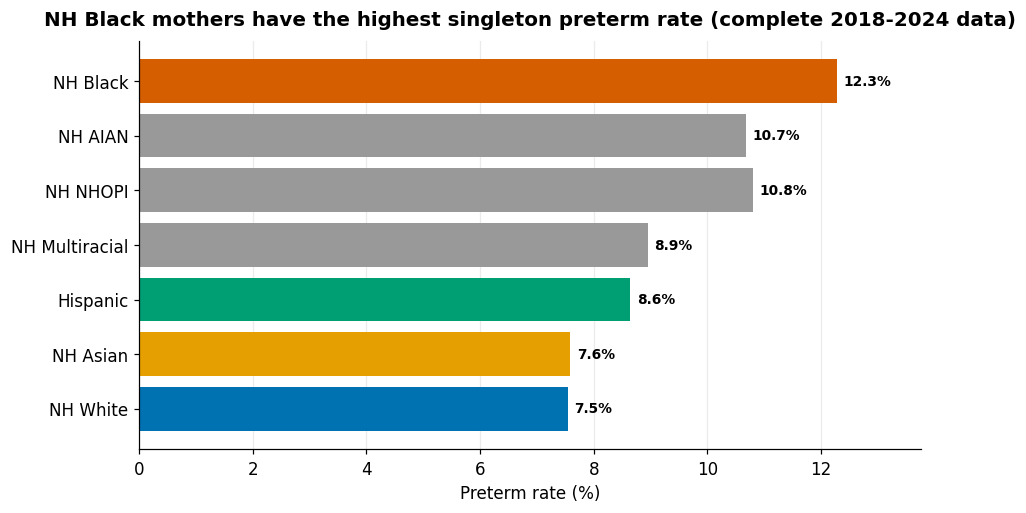

NH Black 12.28% vs NH White 7.54%  ->  gap 4.74 percentage points, on the full population.


In [14]:
by_race = (valid.filter(pl.col('mother_race_ethnicity').is_not_null())
           .group_by('mother_race_ethnicity').agg(rate=pl.col('preterm').mean(), n=pl.len())
           .sort('rate'))
pdf = by_race.to_pandas().set_index('mother_race_ethnicity').reindex([r for r in RACE_ORDER])
fig, ax = plt.subplots()
ax.barh(pdf.index, pdf['rate']*100, color=[RACE_COLOR[r] for r in pdf.index])
for i, v in enumerate(pdf['rate']*100): ax.text(v+0.12, i, f'{v:.1f}%', va='center', fontweight='bold', fontsize=9)
style(ax, 'NH Black mothers have the highest singleton preterm rate (complete 2018-2024 data)', 'Preterm rate (%)', '')
ax.grid(axis='y'); ax.set_xlim(0, (pdf['rate'].max()*100)*1.12); plt.tight_layout(); plt.show()
b = pdf.loc['NH Black','rate']*100; w = pdf.loc['NH White','rate']*100
print(f'NH Black {b:.2f}% vs NH White {w:.2f}%  ->  gap {b-w:.2f} percentage points, on the full population.')

For the record, here are the exact per-race rates behind the bars, so the chart is not the only place the numbers live, plus the headline gap spelled out to two decimals.

In [15]:
print("Per-race singleton preterm rate (%), complete 2018-2024 population (values behind the chart):")
for r in pdf.index:
    print(f"  {r:<16} {pdf.loc[r,'rate']*100:5.2f}%")
print(f"\nNH Black {pdf.loc['NH Black','rate']*100:.2f}% minus NH White "
      f"{pdf.loc['NH White','rate']*100:.2f}% = {(pdf.loc['NH Black','rate']-pdf.loc['NH White','rate'])*100:.2f} pp gap.")

Per-race singleton preterm rate (%), complete 2018-2024 population (values behind the chart):
  NH White          7.54%
  NH Asian          7.58%
  Hispanic          8.64%
  NH Multiracial    8.95%
  NH NHOPI         10.80%
  NH AIAN          10.68%
  NH Black         12.28%

NH Black 12.28% minus NH White 7.54% = 4.74 pp gap.


A **4.7-point** NH Black minus NH White gap, computed on every singleton birth in the country over seven years, not an estimate. And because it is the full census, even the smallest groups (NH NHOPI at about 67,000 births, NH AIAN at about 180,000) give reliable rates, though we still read them with the misclassification caveat from Week 1. This is the disparity the fairness audit will later turn into rigorous, model-based metrics. As always: **race here is a marker of exposure to racism and structural barriers, not a biological cause**, and nothing in this project is a clinical tool.

<a id="plan"></a>
## The plan from here

This week produced the thing the rest of the project stands on: a leakage-safe feature matrix of about 100 pre-delivery features, with the honesty enforced by tests rather than good intentions, plus a stratified working sample split into train, validation, and a large untouched held-out partition for final reporting.

**Next weeks**, in order:

- **Calibrated baseline models.** Logistic regression (as the calibration reference), a decision tree, and a random forest, judged on rate-aware metrics and calibration rather than accuracy. Given how weak the Week 1 signals were, I expect a modest ceiling, and I want to report whatever it is honestly.
- **Gradient boosting and the first fairness read.** XGBoost and LightGBM with proper tuning, then the first formal look at whether the model performs equitably across race groups.
- **A full fairness audit and a decomposition of the gap**, to ask how much of the disparity measured factors can actually account for.

The discipline built this week is what makes those results trustworthy: whatever ceiling we report, we will know it was not inflated by a field that peeked at the answer.

---

Author: [Parshv Patel](https://www.linkedin.com/in/parshv-patel-65a90326b/)  

--- 

Edit Logs:
